In [3]:
from StateDependentAssetModel_GPU import StateDependentAssetModel_GPU

In [4]:
import torch
import math
import numpy as np

# ============================================================
# 0. Core Hyperparameter Configuration
# ============================================================
dt = 1/252
T = 1.0
r = 0.02
d, N, M = 25, 12, 25

num_paths_bounds = 8192 * 4
train_batch_size = 4096
warmup_steps_env = 0
global_seed = 1234

pgd_steps_core = 100
pgd_lr_core = 0.05

# Network architecture and boundary penalty settings
nn_hidden_layers = [64, 64] 
phi_threshold_ratio = 0.03

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
dtype = torch.float64

# ============================================================
# 1. Factor Process Parameters
# ============================================================
# alpha: long-run mean of factors
alpha = np.array([
    0.012, -0.015,  0.008,  0.021, -0.011,  0.014, -0.018,  0.009,  0.016, -0.022,
    0.011, -0.007,  0.019,  0.005, -0.014,  0.022, -0.009,  0.017, -0.013,  0.025,
    0.006, -0.020,  0.015, -0.010,  0.018
])

# beta: mean-reversion matrix (25x25)
beta = np.array([
    [ 1.300,  0.042, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.051,  1.292,  0.038, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.045,  1.283,  0.044, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.048,  1.275,  0.039, -0.002,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.001,  0.002, -0.055,  1.267,  0.041, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.001,  0.002, -0.046,  1.258,  0.037, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.002, -0.004,  0.003, -0.001,  0.002, -0.052,  1.250,  0.045, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.049,  1.242,  0.035, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.042,  1.233,  0.048, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.051,  1.225,  0.036, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.044,  1.217,  0.043, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.047,  1.208,  0.039, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.053,  1.200,  0.046, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.041,  1.192,  0.034, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.050,  1.183,  0.042, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.046,  1.175,  0.038, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.054,  1.167,  0.047, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.043,  1.158,  0.040, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.052,  1.150,  0.045, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.049,  1.142,  0.036, -0.002,  0.004, -0.001,  0.002],
    [ 0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.045,  1.133,  0.043, -0.003,  0.001, -0.004],
    [-0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.056,  1.125,  0.038, -0.002,  0.004],
    [ 0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.047,  1.117,  0.041, -0.003],
    [-0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.051,  1.108,  0.037],
    [ 0.035, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.003, -0.004,  0.001, -0.003,  0.002, -0.004,  0.003, -0.001,  0.002, -0.042,  1.100]
])

# Sigma_V: factor volatility matrix (25x25)
Sigma_V = np.array([
    [ 0.305,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.052,  0.304,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.052,  0.304,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.052,  0.303,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.052,  0.303,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.052,  0.302,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.302,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.301,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.300,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.300,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.299,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.299,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.298,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.297,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.297,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.296,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.296,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002],
    [ 0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.295,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.295,  0.047,  0.001, -0.004,  0.003, -0.002,  0.004],
    [ 0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.294,  0.047,  0.001, -0.004,  0.003, -0.002],
    [-0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.293,  0.047,  0.001, -0.004,  0.003],
    [ 0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.293,  0.047,  0.001, -0.004],
    [-0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.292,  0.047,  0.001],
    [ 0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.292,  0.047],
    [-0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.004,  0.003, -0.002,  0.004, -0.001,  0.052,  0.291]
])

radius = 1.0

# v0: initial factor state vector
v0 = [
    0.08, -0.06,  0.09, -0.07,  0.05, -0.08,  0.07, -0.05,  0.09, -0.06,
    0.08, -0.04,  0.07, -0.09,  0.06, -0.08,  0.05, -0.07,  0.08, -0.06,
    0.09, -0.05,  0.07, -0.08,  0.06
]

# ============================================================
# 2. Asset Drift and Volatility Parameters (mu_0, M_mu, sigma_0, Gamma)
# ============================================================
mu_0 = np.array([
    0.012, 0.013, 0.014, 0.015, 0.018, 0.068,
    0.070, 0.072, 0.075, 0.078, 0.022, 0.024
])

M_mu = np.array([
    [ 0.155,  0.002, -0.003,  0.142,  0.001, -0.002,  0.128,  0.003,  0.001, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002,  0.152, -0.002,  0.001, -0.138,  0.003, -0.001,  0.125, -0.003,  0.001, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.004,  0.001, -0.002,  0.003, -0.001],
    [-0.003,  0.001,  0.148, -0.002,  0.002,  0.135,  0.001, -0.002,  0.122, -0.001,  0.002, -0.004,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.004, -0.001,  0.002, -0.003,  0.001],
    [ 0.092,  0.002, -0.004,  0.001,  0.085,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.004,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.004, -0.002,  0.001, -0.003],
    [ 0.002,  0.095,  0.003, -0.002,  0.001,  0.088,  0.004, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.004,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.004],
    [ 0.028, -0.024,  0.024,  0.001, -0.002,  0.001, -0.003,  0.002,  0.001, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [-0.024,  0.030, -0.028,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.028, -0.024,  0.024, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [-0.030,  0.024, -0.028,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001],
    [ 0.024, -0.030,  0.024, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [ 0.002, -0.001,  0.090,  0.003, -0.001,  0.002,  0.082,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002],
    [-0.002,  0.003, -0.001,  0.088, -0.003,  0.002, -0.001,  0.084, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001]
])


# sigma_0 in R^{N x M} (12x25): row-wise collinear mixing with norm preservation
sigma_0_raw = np.array([
    [ 0.145, -0.012,  0.018, -0.009,  0.015, -0.011,  0.014, -0.007,  0.012, -0.016,  0.009, -0.013,  0.015, -0.011,  0.008, -0.014,  0.012, -0.009,  0.015, -0.011,  0.008, -0.014,  0.012, -0.009,  0.015],
    [-0.014,  0.152, -0.011,  0.016, -0.013,  0.008, -0.015,  0.012, -0.009,  0.014, -0.011,  0.015, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.014,  0.013, -0.009,  0.015, -0.011,  0.013, -0.008],
    [ 0.016, -0.009,  0.138, -0.014,  0.011, -0.015,  0.008, -0.013,  0.015, -0.011,  0.014, -0.009,  0.012, -0.016,  0.011, -0.008,  0.014, -0.012,  0.009, -0.015,  0.011, -0.013,  0.008, -0.016,  0.012],
    [-0.011,  0.015, -0.013,  0.161, -0.009,  0.012, -0.016,  0.011, -0.008,  0.015, -0.013,  0.011, -0.009,  0.014, -0.015,  0.012, -0.008,  0.016, -0.011,  0.009, -0.014,  0.012, -0.015,  0.011, -0.009],
    [ 0.013, -0.014,  0.008, -0.012,  0.149, -0.011,  0.015, -0.009,  0.014, -0.013,  0.008, -0.016,  0.011, -0.009,  0.015, -0.013,  0.011, -0.014,  0.008, -0.016,  0.012, -0.009,  0.015, -0.011,  0.013],
    [-0.009,  0.012, -0.015,  0.011, -0.013,  0.155, -0.008,  0.014, -0.011,  0.009, -0.015,  0.012, -0.014,  0.008, -0.016,  0.011, -0.009,  0.015, -0.013,  0.011, -0.008,  0.016, -0.012,  0.009, -0.014],
    [ 0.015, -0.011,  0.009, -0.016,  0.012, -0.008,  0.142, -0.013,  0.015, -0.009,  0.011, -0.014,  0.008, -0.015,  0.012, -0.007,  0.016, -0.011,  0.009, -0.014,  0.013, -0.008,  0.015, -0.012,  0.009],
    [-0.012,  0.016, -0.011,  0.008, -0.015,  0.013, -0.009,  0.158, -0.012,  0.016, -0.011,  0.009, -0.015,  0.013, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.015,  0.009, -0.013,  0.016, -0.011],
    [ 0.009, -0.013,  0.016, -0.011,  0.008, -0.014,  0.012, -0.015,  0.136, -0.011,  0.016, -0.008,  0.013, -0.012,  0.009, -0.015,  0.011, -0.014,  0.012, -0.008,  0.016, -0.011,  0.009, -0.015,  0.013],
    [-0.015,  0.008, -0.014,  0.012, -0.009,  0.016, -0.011,  0.008, -0.014,  0.164, -0.012,  0.015, -0.009,  0.014, -0.011,  0.008, -0.016,  0.013, -0.009,  0.015, -0.011,  0.014, -0.012,  0.008, -0.016],
    [ 0.011, -0.015,  0.009, -0.013,  0.016, -0.011,  0.008, -0.014,  0.012, -0.016,  0.147, -0.011,  0.009, -0.015,  0.012, -0.016,  0.011, -0.008,  0.014, -0.012,  0.009, -0.016,  0.011, -0.014,  0.008],
    [-0.008,  0.014, -0.012,  0.009, -0.015,  0.011, -0.016,  0.012, -0.009,  0.015, -0.013,  0.151, -0.014,  0.011, -0.008,  0.015, -0.012,  0.009, -0.016,  0.011, -0.014,  0.008, -0.015,  0.012, -0.009]
])

n0 = np.linalg.norm(sigma_0_raw, axis=1, keepdims=True)
sigma_0_new = np.copy(sigma_0_raw)
for i in range(N):
    if i > 0:
        sigma_0_new[i] += 0.35 * sigma_0_raw[i-1]
    if i < N - 1:
        sigma_0_new[i] += 0.35 * sigma_0_raw[i+1]
n1 = np.linalg.norm(sigma_0_new, axis=1, keepdims=True)
sigma_0 = sigma_0_new * (n0 / np.maximum(n1, 1e-12))


Gamma = np.array([
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.002, -0.001,  0.003, -0.002,  0.001,  0.022, -0.002,  0.001, -0.003,  0.002, -0.001,  0.014,  0.002, -0.003,  0.001, -0.002],
    [-0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002,  0.028, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.002,  0.028, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.014,  0.003, -0.001,  0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.028, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.028, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.002, -0.003,  0.014,  0.001, -0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.028,  0.001, -0.002,  0.003, -0.001,  0.002,  0.022, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.028, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.014,  0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003,  0.028, -0.001,  0.002, -0.003,  0.001,  0.022, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.028,  0.002, -0.003,  0.001, -0.002,  0.003,  0.022, -0.001,  0.002, -0.003,  0.001,  0.014]
])


rho_VS = np.array([
    [ 0.090,  0.002, -0.003, -0.090,  0.001, -0.002,  0.090,  0.002, -0.001, -0.090,  0.003, -0.002,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002,  0.090, -0.002,  0.001, -0.090,  0.003, -0.001,  0.090,  0.002, -0.003, -0.090,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [-0.003,  0.001,  0.090, -0.002,  0.003, -0.090,  0.002, -0.001,  0.090,  0.001, -0.002, -0.090,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003],
    [ 0.090, -0.002,  0.001,  0.003, -0.001,  0.090, -0.003,  0.002, -0.002,  0.001,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [ 0.001,  0.090, -0.003,  0.002,  0.003, -0.001,  0.090, -0.002,  0.001, -0.003,  0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003],
    [-0.002,  0.003,  0.090, -0.001,  0.002,  0.001, -0.003,  0.090,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001],
    [ 0.003, -0.001,  0.002,  0.090, -0.002,  0.003,  0.001, -0.001,  0.090,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [-0.001,  0.002, -0.003,  0.001,  0.090, -0.002,  0.003,  0.001, -0.002,  0.003,  0.001,  0.090,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002, -0.001,  0.003, -0.002,  0.001, -0.003,  0.002],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003],
    [-0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001],
    [ 0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002],
    [-0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003],
    [ 0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001],
    [-0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002],
    [ 0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003, -0.001,  0.002, -0.003,  0.001, -0.002,  0.003]
])


# Construct joint correlation matrix from rho_VS
corr_matrix = np.block([
    [np.eye(d),      rho_VS],
    [rho_VS.T,       np.eye(M)]
])
evals = np.linalg.eigvalsh(corr_matrix)
if evals.min() <= 0:
    raise ValueError("Correlation matrix is not positive definite; check rho_VS magnitude.")
np.fill_diagonal(corr_matrix, 1.0)

# ============================================================
# 4. Pack Calibrated Parameters Dictionary
# ============================================================
calibrated_params = {
    'r': float(r),
    'mu_base': mu_0.astype(np.float64),
    'mu_load': M_mu.astype(np.float64),
    'sigma_0': sigma_0.astype(np.float64),
    'gamma_mat': Gamma.astype(np.float64),
    'corr_matrix': corr_matrix.tolist(),
    'sigma_V': Sigma_V.astype(np.float64).tolist(),
    'radius': float(radius)
}

-> [CPU Analysis] Diagnosing latent state factors V ...

📊 Factor Diagnostics Report:
                Path_0  Path_1  Path_2  Path_3  Path_4  Global_Average
Factor_Metrics                                                        
Mean_V1        -0.1038  0.0267  0.1431  0.0286 -0.0203          0.0506
Var_V1          0.0061  0.0044  0.0054  0.0108  0.0024          0.0100
Mean_V2         0.0012 -0.0997  0.1884 -0.0656  0.0474         -0.0400
Var_V2          0.0033  0.0019  0.0186  0.0089  0.0081          0.0101
Mean_V3         0.0872  0.0716 -0.0504  0.1803  0.1913          0.0545
Var_V3          0.0165  0.0278  0.0028  0.0051  0.0245          0.0103
Mean_V4        -0.0410 -0.0390 -0.2261  0.0100 -0.0688         -0.0302
Var_V4          0.0137  0.0130  0.0057  0.0124  0.0120          0.0104
Mean_V5         0.2364  0.1344  0.1270 -0.0639  0.2054          0.0241
Var_V5          0.0066  0.0277  0.0022  0.0083  0.0249          0.0102
Mean_V6         0.0213 -0.1435  0.1238  0.1548  0.0152        

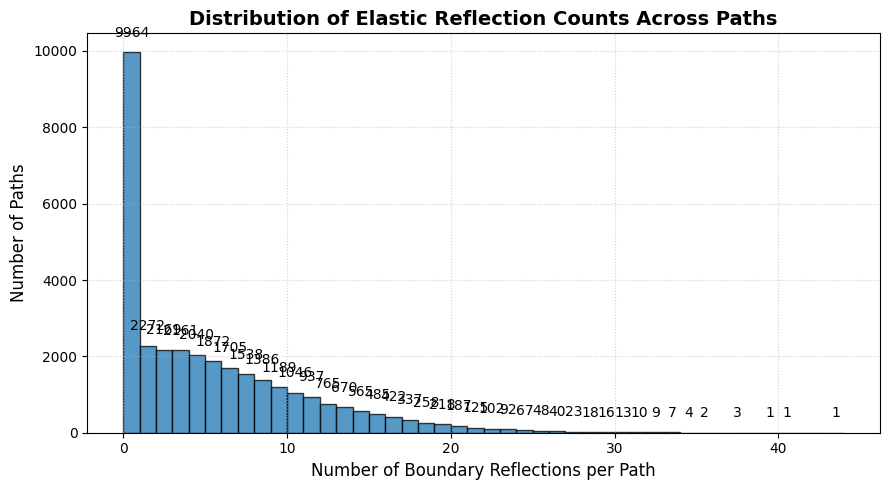

-> [CPU Analysis] Comparing multi-asset steady-state analytical values with Monte Carlo estimates...

📈 Asset Performance Analysis Completed!
               Theoretical  Path_0  Path_1  Path_2  Path_3  Path_4  Global_Average  Bias(Avg-Theory)
Asset_Metrics                                                                                       
Return_S1           0.0022  0.0892  0.1051 -0.0790  0.1168  0.0374          0.0092            0.0070
Return_S2          -0.0000  0.0310  0.2017 -0.0492  0.1263  0.1025         -0.0138           -0.0138
Return_S3           0.0075  0.1677 -0.1096 -0.2236  0.1766  0.2392          0.0144            0.0069
Return_S4           0.0003  0.1162 -0.2793 -0.3146 -0.0500  0.2271          0.0038            0.0035
Return_S5           0.0049 -0.1725 -0.1389 -0.0931  0.0228  0.1836         -0.0019           -0.0068
Return_S6           0.0553 -0.1077 -0.1447 -0.0115 -0.0788  0.1253          0.0584            0.0032
Return_S7           0.0573  0.2046 -0.1327  0.0152

In [5]:


env_bounds = StateDependentAssetModel_GPU(
    d_dim=d, N_dim=N, M_dim=M,
    alpha=alpha, beta=beta, sigma_V=Sigma_V, radius=radius,
    mu_base=mu_0, mu_load=M_mu, sigma_0=sigma_0, gamma_mat=Gamma,
    corr_matrix=corr_matrix.tolist(),
    dt=dt, T=T, num_paths=num_paths_bounds, warmup_steps=warmup_steps_env,
    device=device
)

V_tensor_bounds, _, dW_S_tensor_bounds, Xi_tensor_bounds = env_bounds.simulate(
    v0=v0, return_full_path=True, verbose=False, auto_analyze=False, seed=global_seed
)

df_factors = env_bounds.analyze_factors(print_limit=5, visualize_reflection=True)
df_assets = env_bounds.analyze_scenarios(print_limit=5)



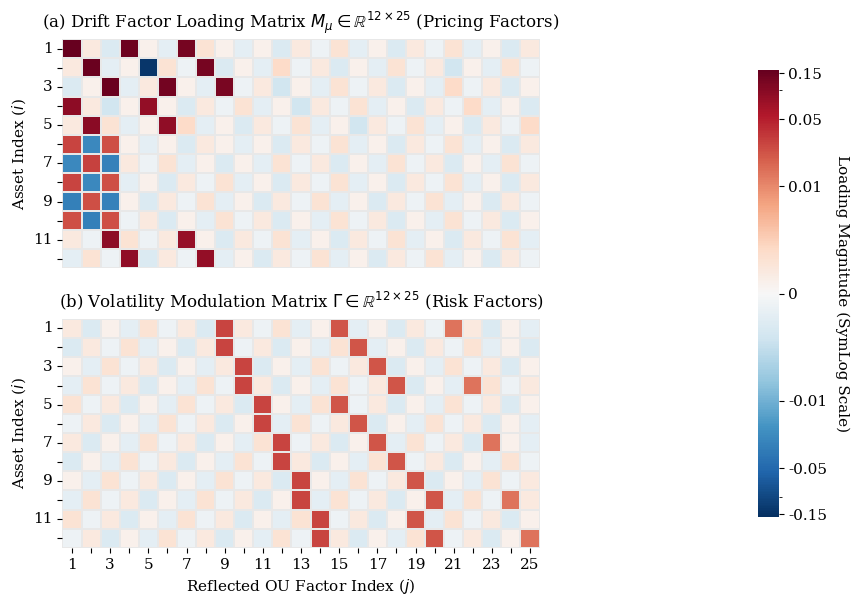

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import SymLogNorm

plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.titlesize': 12,
    'axes.labelsize': 11
})

norm_asset = SymLogNorm(linthresh=0.01, vmin=-0.16, vmax=0.16, base=10)
m_dim, n_dim = M_mu.shape
xticklabels = [str(j) if j % 2 == 1 else "" for j in range(1, n_dim + 1)]
yticklabels = [str(i) if i % 2 == 1 else "" for i in range(1, m_dim + 1)]

fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.2), sharex=True)
cbar_ax = fig.add_axes([0.91, 0.15, 0.02, 0.72])  # [left, bottom, width, height]

sns.heatmap(
    M_mu, ax=axes[0], cmap="RdBu_r", norm=norm_asset,
    square=True, linewidths=0.3, linecolor='#e8e8e8',
    cbar=True, cbar_ax=cbar_ax,
    xticklabels=xticklabels, yticklabels=yticklabels
)
axes[0].set_title(r"(a) Drift Factor Loading Matrix $M_\mu \in \mathbb{R}^{12 \times 25}$ (Pricing Factors)", pad=8)
axes[0].set_ylabel("Asset Index ($i$)")
axes[0].tick_params(axis='x', length=0)

sns.heatmap(
    Gamma, ax=axes[1], cmap="RdBu_r", norm=norm_asset,
    square=True, linewidths=0.3, linecolor='#e8e8e8',
    cbar=False,
    xticklabels=xticklabels, yticklabels=yticklabels
)
axes[1].set_title(r"(b) Volatility Modulation Matrix $\Gamma \in \mathbb{R}^{12 \times 25}$ (Risk Factors)", pad=8)
axes[1].set_xlabel("Reflected OU Factor Index ($j$)")
axes[1].set_ylabel("Asset Index ($i$)")
axes[1].tick_params(axis='y', rotation=0)
axes[0].tick_params(axis='y', rotation=0)

cbar_ax.set_ylabel("Loading Magnitude (SymLog Scale)", rotation=270, labelpad=16)
cbar_ticks = [-0.15, -0.05, -0.01, 0.0, 0.01, 0.05, 0.15]
cbar_ax.set_yticks(cbar_ticks)
cbar_ax.set_yticklabels([f"{t:g}" for t in cbar_ticks])

plt.subplots_adjust(left=0.07, right=0.88, top=0.92, bottom=0.10, hspace=0.22)
plt.savefig("factor_loadings_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()